# Oxygen Respiration Analysis
**Pyro FireSting O2 Logger — 4-Channel Oxygen & Temperature Data**

This notebook:
1. Reads the raw Pyro logger file and converts % air saturation → µmol/L O₂
2. Displays an interactive plot of all four channels + temperature
3. Lets you subset each channel to a time interval of interest
4. Runs a linear regression and reports the respiration rate in µmol O₂ / L / h

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

print('Libraries loaded.')

Libraries loaded.


## 2. User-Defined Parameters

**Edit this cell before running anything else.**

In [2]:
# ── FILE PATH ─────────────────────────────────────────────────────────────────
DATA_FILE = 'Miloefagprojekt26-WholePeriod.txt'   # path to the Pyro logger .txt file

# ── CONVERSION CONSTANTS ──────────────────────────────────────────────────────
SALINITY    = 20.0   # PSU  — assumed constant throughout the experiment
TEMPERATURE = 20.0   # °C   — fixed temperature used ONLY for µmol/L conversion
#                              (the measured temperature is still plotted on the graph)

print(f'Data file  : {DATA_FILE}')
print(f'Salinity   : {SALINITY} PSU')
print(f'Temperature: {TEMPERATURE} °C  (for O₂ solubility calculation)')

Data file  : Miloefagprojekt26-WholePeriod.txt
Salinity   : 20.0 PSU
Temperature: 20.0 °C  (for O₂ solubility calculation)


## 3. Load & Parse the Data File

In [3]:
def parse_pyro_file(filepath):
    """
    Read a Pyro FireSting O2 tab-delimited file.

    The file has a multi-line header with duplicate column names,
    European decimal commas (e.g. '17,160'), and '---' for missing
    values.  We read by column position to avoid pandas duplicate-
    column issues.

    Column positions (0-indexed) in the data rows:
      0   Date
      1   Time (HH:MM:SS)
      2   Time (s)  <- elapsed seconds from experiment start
      4   Ch1 (% air sat)
      5   Ch2 (% air sat)
      6   Ch3 (% air sat)
      7   Ch4 (% air sat)
     14   Temperature — Temp. Probe (°C)
    """
    with open(filepath, 'rb') as fh:
        raw = fh.read().decode('latin-1')

    lines = raw.replace('\r\n', '\n').split('\n')

    # Locate the data header row
    header_idx = None
    for i, line in enumerate(lines):
        if line.startswith('Date') and 'Time (HH:MM:SS)' in line:
            header_idx = i
            break
    if header_idx is None:
        raise ValueError('Could not find data header row. Is this a Pyro FireSting file?')

    # Collect data rows as plain lists (avoids pandas duplicate-column issues)
    rows = []
    for line in lines[header_idx + 1:]:
        if not line.strip():
            continue
        parts = line.split('\t')
        if len(parts) < 15:
            continue
        rows.append(parts)

    # Build DataFrame with integer column indices
    df_raw = pd.DataFrame(rows)   # columns are 0, 1, 2, ...

    # Replace European decimal commas and convert to float
    # (skip col 0=Date, 1=Time string, 3=Comment)
    for col in df_raw.columns:
        if col in (0, 1, 3):
            continue
        df_raw[col] = pd.to_numeric(
            df_raw[col].astype(str).str.replace(',', '.', regex=False),
            errors='coerce'
        )

    # Build a clean named DataFrame
    df = pd.DataFrame({
        'Date'        : df_raw[0],
        'Time'        : df_raw[1],
        'elapsed_s'   : pd.to_numeric(df_raw[2], errors='coerce'),
        'Ch1_pct'     : pd.to_numeric(df_raw[4], errors='coerce'),
        'Ch2_pct'     : pd.to_numeric(df_raw[5], errors='coerce'),
        'Ch3_pct'     : pd.to_numeric(df_raw[6], errors='coerce'),
        'Ch4_pct'     : pd.to_numeric(df_raw[7], errors='coerce'),
        'Temp_C'      : pd.to_numeric(df_raw[14], errors='coerce'),
    })

    df['elapsed_hours'] = df['elapsed_s'] / 3600.0
    return df


df = parse_pyro_file(r'..\\Experiment\Data\Miloefagprojekt26-WholePeriod.txt')

print(f'Loaded {len(df):,} rows')
print(f'Time span   : {df["elapsed_hours"].max():.1f} hours')
print(f'Start       : {df["Date"].iloc[0]}  {df["Time"].iloc[0]}')
print(f'End         : {df["Date"].iloc[-1]}  {df["Time"].iloc[-1]}')
print(f'Temp range  : {df["Temp_C"].min():.2f} – {df["Temp_C"].max():.2f} °C')

df[['elapsed_hours', 'Ch1_pct', 'Ch2_pct', 'Ch3_pct', 'Ch4_pct', 'Temp_C']].head()

Loaded 41,629 rows
Time span   : 115.6 hours
Start       : 29-04-2026  14:44:01
End         : 04-05-2026  10:22:01
Temp range  : 14.37 – 19.24 °C


,elapsed_hours,Ch1_pct,Ch2_pct,Ch3_pct,Ch4_pct,Temp_C
0,0.000000,103.30,100.21,99.796,99.678,17.160
1,0.002778,103.21,100.14,99.751,100.460,17.139
2,0.005556,103.34,100.24,99.803,100.140,17.138
3,0.008333,103.22,100.13,99.755,100.350,17.154
4,0.011111,103.27,100.53,99.756,100.260,17.169


## 4. Convert % Air Saturation → µmol/L

Uses the **Garcia & Gordon (1992)** O₂ solubility equation:

$$[\mathrm{O}_2]_{\mu\mathrm{mol/L}} = \frac{\%_{\mathrm{air\,sat}}}{100} \times O_2^{\mathrm{sat}}(T,\,S)$$

where $O_2^{\mathrm{sat}}$ is the equilibrium oxygen solubility at the fixed  
temperature and salinity defined in Section 2.

In [4]:
def garcia_gordon_o2sat(temp_C, salinity_psu):
    """
    Garcia & Gordon (1992) O2 solubility in µmol/L.
    Valid range: 0–40 °C, 0–42 PSU.

    Returns
    -------
    float : equilibrium O2 concentration (µmol/L)
    """
    Ts = np.log((298.15 - temp_C) / (273.15 + temp_C))  # scaled temperature
    S  = salinity_psu

    # Bunsen solubility coefficients (Table 1, Garcia & Gordon 1992)
    A  = [5.80818, 3.20684, 4.11890, 4.93845, 1.01567, 1.41575]
    B  = [-7.01211e-3, -7.25958e-3, -7.93334e-3, -5.54491e-3]
    C0 = -1.32412e-7

    lnO2 = (A[0] + A[1]*Ts + A[2]*Ts**2 + A[3]*Ts**3 + A[4]*Ts**4 + A[5]*Ts**5
            + S * (B[0] + B[1]*Ts + B[2]*Ts**2 + B[3]*Ts**3)
            + C0 * S**2)

    O2_umol_kg = np.exp(lnO2)   # µmol/kg seawater

    # Convert µmol/kg → µmol/L  (Millero & Poisson 1981 density approx)
    rho = 1000.0 + 0.8 * salinity_psu - 0.2 * temp_C   # kg/m³
    return O2_umol_kg * (rho / 1000.0)


O2_SAT = garcia_gordon_o2sat(TEMPERATURE, SALINITY)
print(f'O₂ saturation at {TEMPERATURE} °C, S = {SALINITY} PSU : {O2_SAT:.3f} µmol/L')

# Convert all four channels
PCT_COLS  = ['Ch1_pct',   'Ch2_pct',   'Ch3_pct',   'Ch4_pct'  ]
UMOL_COLS = ['Ch1_umolL', 'Ch2_umolL', 'Ch3_umolL', 'Ch4_umolL']

for pct, umol in zip(PCT_COLS, UMOL_COLS):
    df[umol] = (df[pct] / 100.0) * O2_SAT

df[['elapsed_hours'] + PCT_COLS + UMOL_COLS].head(3)

O₂ saturation at 20.0 °C, S = 20.0 PSU : 251.952 µmol/L


,elapsed_hours,Ch1_pct,Ch2_pct,Ch3_pct,Ch4_pct,Ch1_umolL,Ch2_umolL,Ch3_umolL,Ch4_umolL
0,0.000000,103.30,100.21,99.796,99.678,260.265925,252.480623,251.437544,251.140241
1,0.002778,103.21,100.14,99.751,100.460,260.039169,252.304257,251.324166,253.110502
2,0.005556,103.34,100.24,99.803,100.140,260.366706,252.556209,251.455180,252.304257


## 5. Interactive Plot — All Channels + Temperature

- **Left y-axis** : Dissolved oxygen (µmol/L) — all four channels
- **Right y-axis** : Temperature (°C, Temp. Probe)
- **x-axis** : Elapsed time (hours since start)

Use the Plotly toolbar (top-right) to zoom, pan, and reset.  
Click legend entries to toggle channels on/off.  
Double-click a legend entry to isolate that channel.

In [5]:
CH_COLORS = {
    'Ch1_umolL': '#1f77b4',  # blue
    'Ch2_umolL': '#ff7f0e',  # orange
    'Ch3_umolL': '#2ca02c',  # green
    'Ch4_umolL': '#d62728',  # red
}
CH_LABELS = {
    'Ch1_umolL': 'Ch 1 — Oxygen Sensor Spot',
    'Ch2_umolL': 'Ch 2 — Oxygen Robust Probe',
    'Ch3_umolL': 'Ch 3 — Robust Oxygen Probe',
    'Ch4_umolL': 'Ch 4 — Oxygen Minisensor',
}

fig = make_subplots(specs=[[{'secondary_y': True}]])

# Oxygen channels (primary y-axis)
for col in UMOL_COLS:
    fig.add_trace(
        go.Scatter(
            x=df['elapsed_hours'],
            y=df[col],
            mode='lines',
            name=CH_LABELS[col],
            line=dict(color=CH_COLORS[col], width=1.5),
            hovertemplate=(
                f'<b>{CH_LABELS[col]}</b><br>'
                'Time : %{x:.3f} h<br>'
                'O₂   : %{y:.2f} µmol/L'
                '<extra></extra>'
            ),
        ),
        secondary_y=False,
    )

# Temperature (secondary y-axis)
if df['Temp_C'].notna().any():
    fig.add_trace(
        go.Scatter(
            x=df['elapsed_hours'],
            y=df['Temp_C'],
            mode='lines',
            name='Temperature (°C)',
            line=dict(color='rgba(100,100,100,0.7)', width=1.2, dash='dot'),
            hovertemplate=(
                '<b>Temperature</b><br>'
                'Time : %{x:.3f} h<br>'
                'Temp : %{y:.2f} °C'
                '<extra></extra>'
            ),
        ),
        secondary_y=True,
    )

fig.update_layout(
    title=dict(
        text='FireSting O₂ — Dissolved Oxygen (µmol/L) & Temperature',
        font_size=15,
    ),
    xaxis=dict(
        title='Elapsed time (hours)',
        showgrid=True, gridcolor='#e8e8e8',
    ),
    legend=dict(
        x=0.01, y=0.01,
        bgcolor='rgba(255,255,255,0.9)',
        bordercolor='#cccccc', borderwidth=1,
        xanchor='left',
        yanchor='bottom',
    ),
    hovermode='x unified',
    height=520,
    plot_bgcolor='white',
    paper_bgcolor='white',
)
fig.update_yaxes(
    title_text='Dissolved oxygen (µmol/L)',
    showgrid=True, gridcolor='#e8e8e8',
    secondary_y=False,
)
fig.update_yaxes(
    title_text='Temperature (°C)',
    showgrid=False,
    secondary_y=True,
)

fig.show()

## 6. Subset Each Channel to a Time Interval

Edit `INTERVALS` so each channel covers the time window you want to analyse.  
You can set **different intervals per channel**, or use `None` to keep the full time series.

In [6]:
# ── EDIT THESE INTERVALS (hours elapsed) ─────────────────────────────────────
INTERVALS = {
    'Ch1_umolL': (1.0, 5.0),   # (start_hour, end_hour)  or  None for full series
    'Ch2_umolL': (25.0, 28.0),
    'Ch3_umolL': (25.0, 28.0),
    'Ch4_umolL': (1.0, 5.0),
}
# ─────────────────────────────────────────────────────────────────────────────

subsets = {}
for ch, interval in INTERVALS.items():
    if interval is None:
        sub = df[['elapsed_hours', ch, 'Temp_C']].dropna(subset=[ch]).copy()
    else:
        t0_h, t1_h = interval
        mask = (df['elapsed_hours'] >= t0_h) & (df['elapsed_hours'] <= t1_h)
        sub = df.loc[mask, ['elapsed_hours', ch, 'Temp_C']].dropna(subset=[ch]).copy()
    subsets[ch] = sub

    n    = len(sub)
    span = f"{sub['elapsed_hours'].min():.2f} – {sub['elapsed_hours'].max():.2f} h"
    orng = f"{sub[ch].min():.1f} – {sub[ch].max():.1f} µmol/L"
    print(f'{ch:12s}  {n:6,} points   {span}   O₂: {orng}')

print('\nSubsets ready.')

Ch1_umolL      1,441 points   1.00 – 5.00 h   O₂: 263.5 – 266.7 µmol/L
Ch2_umolL      1,081 points   25.00 – 28.00 h   O₂: 205.3 – 217.6 µmol/L
Ch3_umolL      1,081 points   25.00 – 28.00 h   O₂: 207.1 – 216.2 µmol/L
Ch4_umolL      1,441 points   1.00 – 5.00 h   O₂: 236.2 – 246.3 µmol/L

Subsets ready.


### 6b. Preview Subsets
Bold lines = selected interval; faded lines = full series.

In [7]:
fig2 = make_subplots(specs=[[{'secondary_y': True}]])

for col in UMOL_COLS:
    # Full series (faded background)
    fig2.add_trace(
        go.Scatter(
            x=df['elapsed_hours'], y=df[col],
            mode='lines',
            name=CH_LABELS[col] + ' (full)',
            line=dict(color=CH_COLORS[col], width=1),
            opacity=0.20,
            showlegend=True,
        ),
        secondary_y=False,
    )
    # Selected subset (full opacity)
    sub = subsets[col]
    fig2.add_trace(
        go.Scatter(
            x=sub['elapsed_hours'], y=sub[col],
            mode='lines',
            name=CH_LABELS[col] + ' (subset)',
            line=dict(color=CH_COLORS[col], width=2.5),
        ),
        secondary_y=False,
    )

if df['Temp_C'].notna().any():
    fig2.add_trace(
        go.Scatter(
            x=df['elapsed_hours'], y=df['Temp_C'],
            mode='lines', name='Temperature (°C)',
            line=dict(color='gray', width=1, dash='dot'), opacity=0.5,
        ),
        secondary_y=True,
    )

fig2.update_layout(
    title='Subsetted Intervals (bright = selected window)',
    xaxis=dict(title='Elapsed time (hours)', showgrid=True, gridcolor='#e8e8e8'),
    hovermode='x unified', height=520,
    plot_bgcolor='white', paper_bgcolor='white',
    legend=dict(x=1.07, y=1, bgcolor='rgba(255,255,255,0.9)', bordercolor='#ccc', borderwidth=1),
)
fig2.update_yaxes(title_text='Dissolved oxygen (µmol/L)', showgrid=True, gridcolor='#e8e8e8', secondary_y=False)
fig2.update_yaxes(title_text='Temperature (°C)', secondary_y=True)
fig2.show()

## 7. Linear Regression → Respiration Rate

Set `REG_CHANNEL` to the channel you want and `REG_INTERVAL` to the time window.  
The **slope** of the linear fit = **respiration rate in µmol O₂ / L / h**.  
A negative slope means oxygen is being consumed (expected for respiration).

> The interval here does **not** have to match `INTERVALS` above —  
> zoom into the interactive plot in Section 5 to identify a good linear portion first.

In [8]:
COLORS = ['steelblue', 'tomato', 'seagreen', 'mediumpurple']

def linear_regression(REG_CHANNELS, REG_INTERVAL):
    if not (2 <= len(REG_CHANNELS) <= 4):
        raise ValueError('REG_CHANNELS must contain between 2 and 4 channels.')

    t0_reg, t1_reg = REG_INTERVAL
    mask = (df['elapsed_hours'] >= t0_reg) & (df['elapsed_hours'] <= t1_reg)

    fig, ax = plt.subplots(figsize=(10, 5))

    for REG_CHANNEL, color in zip(REG_CHANNELS, COLORS):
        reg_df = df.loc[mask, ['elapsed_hours', REG_CHANNEL]].dropna()

        if len(reg_df) < 5:
            raise ValueError(
                f'Only {len(reg_df)} data points in [{t0_reg}, {t1_reg}] h. '
                'Widen REG_INTERVAL or check your channel selection.'
            )

        x = reg_df['elapsed_hours'].values
        y = reg_df[REG_CHANNEL].values

        slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
        y_fit = slope * x + intercept

        print('=' * 62)
        print(f'  Channel        : {CH_LABELS[REG_CHANNEL]}')
        print(f'  Interval       : {t0_reg:.2f} – {t1_reg:.2f} h')
        print(f'  N data points  : {len(reg_df):,}')
        print('─' * 62)
        print(f'  Slope          : {slope:+.5f}  µmol/L/h')
        print(f'  Intercept      : {intercept:.4f}  µmol/L')
        print(f'  R²             : {r_value**2:.5f}')
        print(f'  p-value        : {p_value:.2e}')
        print(f'  Std Error      : {std_err:.5f}  µmol/L/h')
        print('─' * 62)
        print(f'  ▶  RESPIRATION RATE : {slope:+.5f} µmol O₂ / L / h')
        print(f'     95% CI           : [{slope - 1.96*std_err:.5f},  {slope + 1.96*std_err:.5f}]')
        print()
        if slope < 0:
            print('  Negative slope → oxygen is being consumed (respiration). ✓')
        else:
            print('  ⚠  Positive slope — oxygen is increasing in this window.')
        print('=' * 62)

        ax.scatter(x, y, color=color, s=3, zorder=3,
                   label=f'{CH_LABELS[REG_CHANNEL]} data')
        ax.plot(x, y_fit, color=color, linewidth=2, zorder=4,
                label=f'{CH_LABELS[REG_CHANNEL]} fit  (R²={r_value**2:.4f}, {slope:+.4f} µmol/L/h)')

    ax.set_xlabel('Elapsed time (h)')
    ax.set_ylabel('O₂ (µmol/L)')
    ax.set_title(f'Linear Regression  |  {t0_reg:.2f} – {t1_reg:.2f} h')
    ax.legend(fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

### Hour 1-5

  Channel        : Ch 1 — Oxygen Sensor Spot
  Interval       : 15.00 – 20.00 h
  N data points  : 1,801
──────────────────────────────────────────────────────────────
  Slope          : -1.46390  µmol/L/h
  Intercept      : 262.6694  µmol/L
  R²             : 0.98504
  p-value        : 0.00e+00
  Std Error      : 0.00425  µmol/L/h
──────────────────────────────────────────────────────────────
  ▶  RESPIRATION RATE : -1.46390 µmol O₂ / L / h
     95% CI           : [-1.47223,  -1.45556]

  Negative slope → oxygen is being consumed (respiration). ✓
  Channel        : Ch 4 — Oxygen Minisensor
  Interval       : 15.00 – 20.00 h
  N data points  : 1,801
──────────────────────────────────────────────────────────────
  Slope          : -3.89725  µmol/L/h
  Intercept      : 284.9757  µmol/L
  R²             : 0.96744
  p-value        : 0.00e+00
  Std Error      : 0.01686  µmol/L/h
──────────────────────────────────────────────────────────────
  ▶  RESPIRATION RATE : -3.89725 µmol O₂ / L / h
 

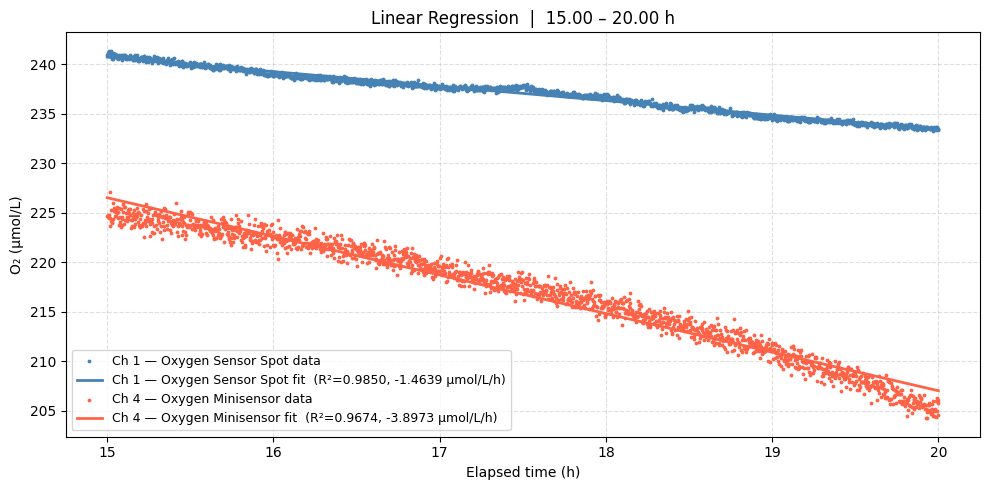

In [15]:
REG_CHANNELS = ['Ch1_umolL', 'Ch4_umolL']          # 2 to 4 channels
REG_INTERVAL = (15.0, 20.0)                           # (start_hour, end_hour)
linear_regression(REG_CHANNELS, REG_INTERVAL)

### Hour 25-28

  Channel        : Ch 1 — Oxygen Sensor Spot
  Interval       : 25.00 – 28.00 h
  N data points  : 1,081
──────────────────────────────────────────────────────────────
  Slope          : -1.06222  µmol/L/h
  Intercept      : 254.6258  µmol/L
  R²             : 0.96001
  p-value        : 0.00e+00
  Std Error      : 0.00660  µmol/L/h
──────────────────────────────────────────────────────────────
  ▶  RESPIRATION RATE : -1.06222 µmol O₂ / L / h
     95% CI           : [-1.07515,  -1.04928]

  Negative slope → oxygen is being consumed (respiration). ✓
  Channel        : Ch 2 — Oxygen Robust Probe
  Interval       : 25.00 – 28.00 h
  N data points  : 1,081
──────────────────────────────────────────────────────────────
  Slope          : -3.99869  µmol/L/h
  Intercept      : 316.7247  µmol/L
  R²             : 0.98405
  p-value        : 0.00e+00
  Std Error      : 0.01550  µmol/L/h
──────────────────────────────────────────────────────────────
  ▶  RESPIRATION RATE : -3.99869 µmol O₂ / L / h

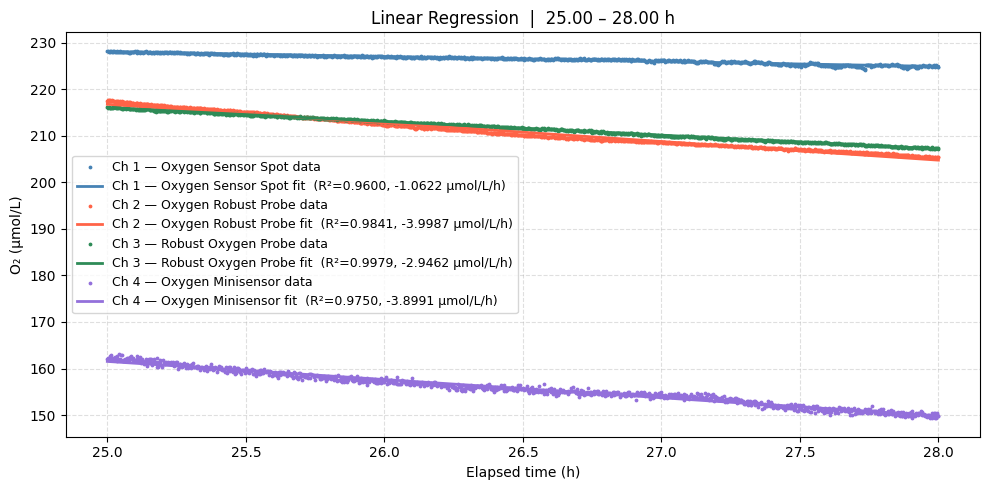

In [10]:
REG_CHANNELS = ['Ch1_umolL', 'Ch2_umolL', 'Ch3_umolL', 'Ch4_umolL'] # 2 to 4 channels
REG_INTERVAL = (25.0, 28.0)                           # (start_hour, end_hour)
linear_regression(REG_CHANNELS, REG_INTERVAL)

### Hour 50-60

  Channel        : Ch 1 — Oxygen Sensor Spot
  Interval       : 50.00 – 60.00 h
  N data points  : 3,601
──────────────────────────────────────────────────────────────
  Slope          : -0.06860  µmol/L/h
  Intercept      : 212.9442  µmol/L
  R²             : 0.36469
  p-value        : 0.00e+00
  Std Error      : 0.00151  µmol/L/h
──────────────────────────────────────────────────────────────
  ▶  RESPIRATION RATE : -0.06860 µmol O₂ / L / h
     95% CI           : [-0.07156,  -0.06564]

  Negative slope → oxygen is being consumed (respiration). ✓
  Channel        : Ch 2 — Oxygen Robust Probe
  Interval       : 50.00 – 60.00 h
  N data points  : 3,601
──────────────────────────────────────────────────────────────
  Slope          : -2.53454  µmol/L/h
  Intercept      : 269.3739  µmol/L
  R²             : 0.97344
  p-value        : 0.00e+00
  Std Error      : 0.00698  µmol/L/h
──────────────────────────────────────────────────────────────
  ▶  RESPIRATION RATE : -2.53454 µmol O₂ / L / h

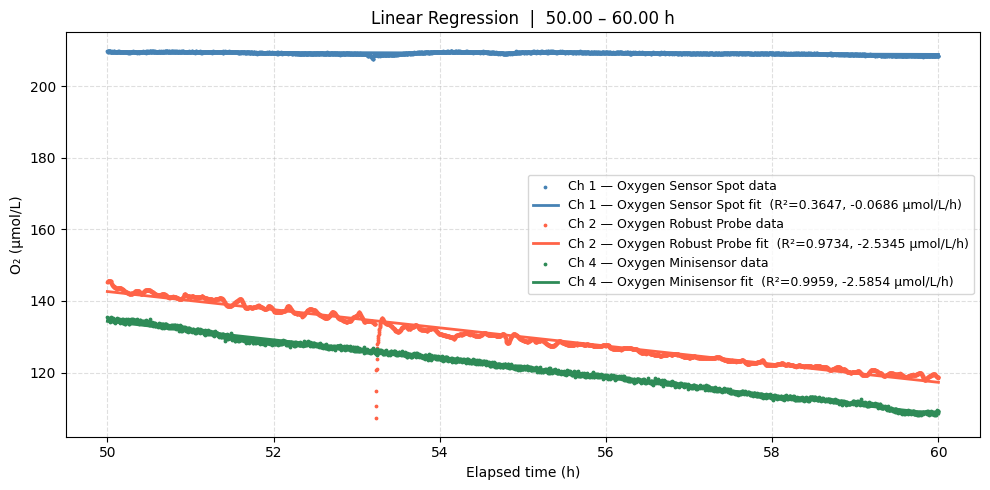

In [11]:
REG_CHANNELS = ['Ch1_umolL', 'Ch2_umolL', 'Ch4_umolL']          # 2 to 4 channels
REG_INTERVAL = (50.0, 60.0)                           # (start_hour, end_hour)
linear_regression(REG_CHANNELS, REG_INTERVAL)

### Hour 100-114

  Channel        : Ch 1 — Oxygen Sensor Spot
  Interval       : 100.00 – 114.00 h
  N data points  : 5,041
──────────────────────────────────────────────────────────────
  Slope          : -0.03757  µmol/L/h
  Intercept      : 219.7787  µmol/L
  R²             : 0.07367
  p-value        : 7.69e-86
  Std Error      : 0.00188  µmol/L/h
──────────────────────────────────────────────────────────────
  ▶  RESPIRATION RATE : -0.03757 µmol O₂ / L / h
     95% CI           : [-0.04125,  -0.03390]

  Negative slope → oxygen is being consumed (respiration). ✓
  Channel        : Ch 2 — Oxygen Robust Probe
  Interval       : 100.00 – 114.00 h
  N data points  : 5,041
──────────────────────────────────────────────────────────────
  Slope          : -0.92118  µmol/L/h
  Intercept      : 154.7622  µmol/L
  R²             : 0.98436
  p-value        : 0.00e+00
  Std Error      : 0.00164  µmol/L/h
──────────────────────────────────────────────────────────────
  ▶  RESPIRATION RATE : -0.92118 µmol O₂ / L

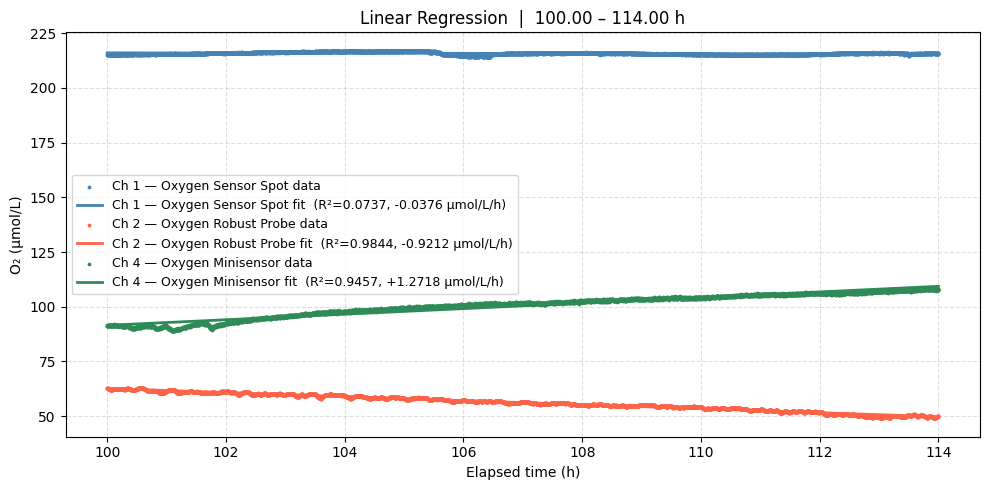

In [12]:
REG_CHANNELS = ['Ch1_umolL', 'Ch2_umolL', 'Ch4_umolL']          # 2 to 4 channels
REG_INTERVAL = (100.0, 114.0)                           # (start_hour, end_hour)
linear_regression(REG_CHANNELS, REG_INTERVAL)

### 7b. Regression Plot

In [13]:
REG_CHANNEL  = ['Ch1_umolL', 'Ch2_umolL', 'Ch3_umolL', 'Ch4_umolL']
REG_INTERVAL = (25.0, 28.0)

for ch in REG_CHANNEL:
    t0_reg, t1_reg = REG_INTERVAL
    mask   = (df['elapsed_hours'] >= t0_reg) & (df['elapsed_hours'] <= t1_reg)
    reg_df = df.loc[mask, ['elapsed_hours', ch]].dropna()

    if len(reg_df) < 5:
        print(f'⚠ {ch}: only {len(reg_df)} points in [{t0_reg}, {t1_reg}] h — skipped.')
        continue

    x = reg_df['elapsed_hours'].values
    y = reg_df[ch].values
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    y_fit = slope * x + intercept

    label = CH_LABELS[ch]
    color = CH_COLORS[ch]
    fig3  = go.Figure()

    fig3.add_trace(go.Scatter(
        x=reg_df['elapsed_hours'], y=reg_df[ch],
        mode='lines', name=label,
        line=dict(color=color, width=1.5),
        hovertemplate='Time: %{x:.3f} h<br>O₂: %{y:.2f} µmol/L<extra></extra>',
    ))
    fig3.add_trace(go.Scatter(
        x=x, y=y_fit, mode='lines',
        name=f'Linear fit  (slope = {slope:+.4f} µmol/L/h)',
        line=dict(color='black', width=2.2, dash='dash'),
    ))
    fig3.add_annotation(
        xref='paper', yref='paper', x=0.02, y=0.97,
        showarrow=False, align='left',
        text=(
            f'<b>Respiration rate</b><br>'
            f'Slope = {slope:+.4f} µmol/L/h<br>'
            f'R² = {r_value**2:.4f}<br>'
            f'p = {p_value:.2e}<br>'
            f'SE = {std_err:.4f} µmol/L/h'
        ),
        bgcolor='rgba(255,255,255,0.88)',
        bordercolor='#aaaaaa', borderwidth=1, font=dict(size=12),
    )
    fig3.update_layout(
        title=f'Linear Regression — {label}   [{t0_reg:.1f} – {t1_reg:.1f} h]',
        xaxis=dict(title='Elapsed time (hours)', showgrid=True, gridcolor='#e8e8e8'),
        yaxis=dict(title='Dissolved oxygen (µmol/L)', showgrid=True, gridcolor='#e8e8e8'),
        height=460, plot_bgcolor='white', paper_bgcolor='white', hovermode='x unified',
        legend=dict(x=1.02, y=1, bgcolor='rgba(255,255,255,0.9)', bordercolor='#ccc', borderwidth=1),
    )
    fig3.show()

## 8. Batch Regression — All Channels

Runs a regression for every channel using the intervals defined in `INTERVALS` (Section 6).  
Useful for a quick overview of respiration rates across all chambers.

In [14]:
batch_results = []

for ch, interval in INTERVALS.items():
    if interval is None:
        sub = df[['elapsed_hours', ch]].dropna()
        t_s = sub['elapsed_hours'].min()
        t_e = sub['elapsed_hours'].max()
    else:
        t_s, t_e = interval
        mask = (df['elapsed_hours'] >= t_s) & (df['elapsed_hours'] <= t_e)
        sub  = df.loc[mask, ['elapsed_hours', ch]].dropna()

    if len(sub) < 5:
        print(f'⚠  {ch}: fewer than 5 points in [{t_s}, {t_e}] h — skipped.')
        continue

    sl, ic, rv, pv, se = stats.linregress(sub['elapsed_hours'].values, sub[ch].values)

    batch_results.append({
        'Channel'              : ch,
        'Description'          : CH_LABELS[ch],
        'Start (h)'            : t_s,
        'End (h)'              : t_e,
        'N'                    : len(sub),
        'Slope (µmol/L/h)'     : round(sl, 5),
        'Intercept (µmol/L)'   : round(ic, 3),
        'R²'                   : round(rv**2, 5),
        'p-value'              : f'{pv:.2e}',
        'Std Err (µmol/L/h)'   : round(se, 5),
    })

summary = pd.DataFrame(batch_results)
print('Batch regression — respiration rates (µmol O₂ / L / h):')
summary

Batch regression — respiration rates (µmol O₂ / L / h):


,Channel,Description,Start (h),End (h),N,Slope (µmol/L/h),Intercept (µmol/L),R²,p-value,Std Err (µmol/L/h)
0,Ch1_umolL,Ch 1 — Oxygen Sensor Spot,1.0,5.0,1441,-0.56113,266.592,0.88828,0.00e+00,0.00525
1,Ch2_umolL,Ch 2 — Oxygen Robust Probe,25.0,28.0,1081,-3.99869,316.725,0.98405,0.00e+00,0.01550
2,Ch3_umolL,Ch 3 — Robust Oxygen Probe,25.0,28.0,1081,-2.94623,289.677,0.99792,0.00e+00,0.00409
3,Ch4_umolL,Ch 4 — Oxygen Minisensor,1.0,5.0,1441,-1.54230,245.939,0.83930,0.00e+00,0.01779
